# **1. Perkenalan Dataset**

Dataset yang digunakan dalam eksperimen ini adalah *Plant Disease Prediction Dataset* yang diperoleh dari Kaggle.

Dataset berupa citra tanaman dan memiliki tiga kelas penyakit, yaitu:
1. `Corn_(maize)___Common_rust` — penyakit karat umum pada jagung.
2. `Potato___Early_blight` — penyakit hawar awal pada kentang.
3. `Tomato___Bacterial_spot` — penyakit bercak bakteri pada tomat.

Dataset ini termasuk data tidak terstruktur (*unstructured data*) karena informasi utamanya berbentuk gambar, bukan tabel. Eksperimen dilakukan untuk memahami karakteristik dataset, mengeksplorasi distribusi kelas, dan melakukan preprocessing agar citra dapat digunakan pada tahap pembangunan model Machine Learning.

Sumber: https://www.kaggle.com/datasets/shuvranshu/plant-disease-prediction-dataset

# **2. Import Library**

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from collections import Counter


# **3. Memuat Dataset**

In [2]:
DATASET_DIR = "/kaggle/input/datasets/riokrnwn/plant-disease-prediction-dataset/Dataset"

class_names = sorted([
    name for name in os.listdir(DATASET_DIR)
    if os.path.isdir(os.path.join(DATASET_DIR, name))
])

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
image_paths = []
labels = []

for class_name in class_names:
    class_dir = os.path.join(DATASET_DIR, class_name)

    for filename in os.listdir(class_dir):
        if filename.lower().endswith(image_extensions):
            image_paths.append(os.path.join(class_dir, filename))
            labels.append(class_name)

df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})

print("Jumlah gambar:", len(df))
print("Jumlah kelas:", df["label"].nunique())
print("\nContoh data:")
display(df.head())

print("\nDaftar kelas:")
print(df["label"].value_counts())


Jumlah gambar: 900
Jumlah kelas: 3

Contoh data:


,image_path,label
0,/kaggle/input/datasets/riokrnwn/plant-disease-...,Corn_(maize)___Common_rust_
1,/kaggle/input/datasets/riokrnwn/plant-disease-...,Corn_(maize)___Common_rust_
2,/kaggle/input/datasets/riokrnwn/plant-disease-...,Corn_(maize)___Common_rust_
3,/kaggle/input/datasets/riokrnwn/plant-disease-...,Corn_(maize)___Common_rust_
4,/kaggle/input/datasets/riokrnwn/plant-disease-...,Corn_(maize)___Common_rust_



Daftar kelas:
label
Corn_(maize)___Common_rust_    300
Potato___Early_blight          300
Tomato___Bacterial_spot        300
Name: count, dtype: int64


# **4. Exploratory Data Analysis (EDA)**

,Kelas,Jumlah Gambar
0,Corn_(maize)___Common_rust_,300
1,Potato___Early_blight,300
2,Tomato___Bacterial_spot,300


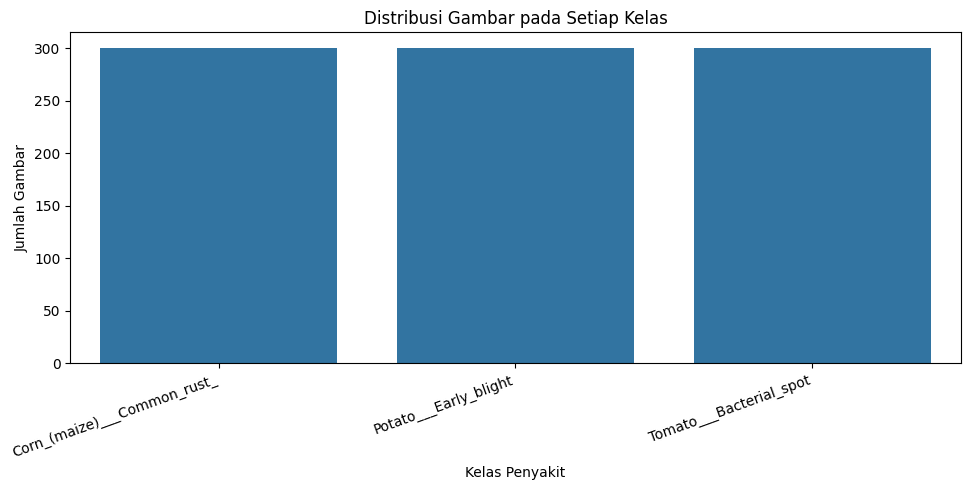

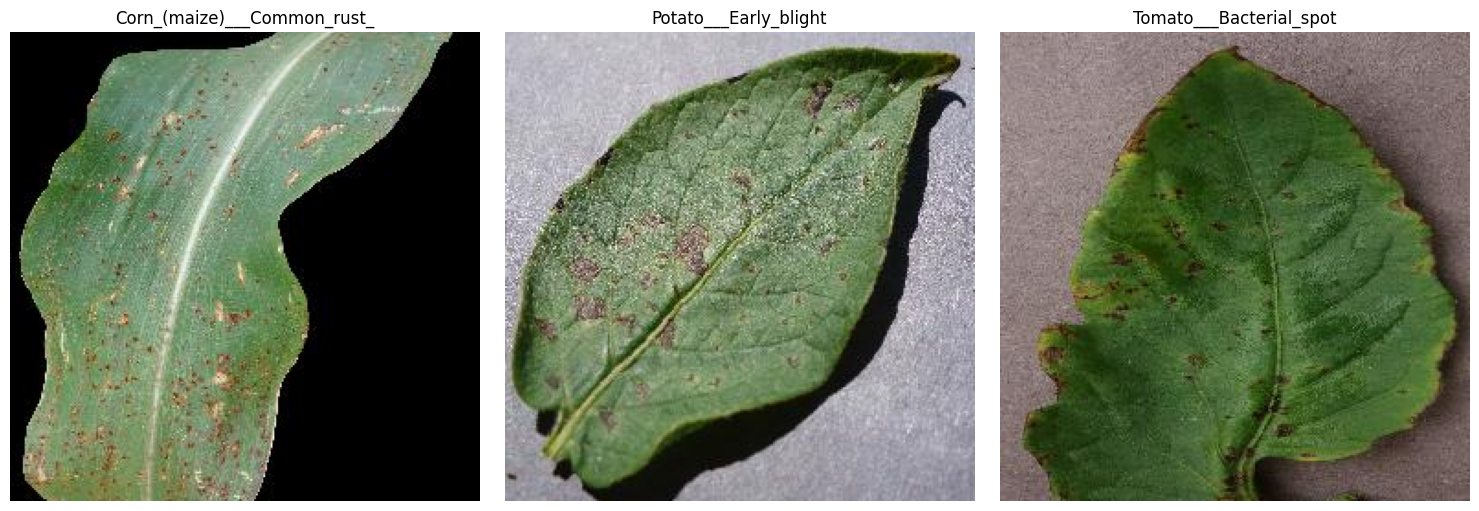

Jumlah gambar yang berhasil diperiksa: 900
Lima ukuran gambar yang paling umum:
[((256, 256), 900)]


In [3]:
# Distribusi jumlah gambar pada setiap kelas
class_counts = df["label"].value_counts().sort_index()

eda_df = class_counts.reset_index()
eda_df.columns = ["Kelas", "Jumlah Gambar"]

display(eda_df)

plt.figure(figsize=(10, 5))
sns.barplot(data=eda_df, x="Kelas", y="Jumlah Gambar")
plt.title("Distribusi Gambar pada Setiap Kelas")
plt.xlabel("Kelas Penyakit")
plt.ylabel("Jumlah Gambar")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# Menampilkan contoh gambar dari setiap kelas
fig, axes = plt.subplots(1, len(class_names), figsize=(5 * len(class_names), 5))

if len(class_names) == 1:
    axes = [axes]

for ax, class_name in zip(axes, class_names):
    sample_path = df.loc[df["label"] == class_name, "image_path"].iloc[0]

    with Image.open(sample_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Memeriksa dimensi gambar
image_sizes = []

for path in df["image_path"]:
    try:
        with Image.open(path) as img:
            image_sizes.append(img.size)
    except (OSError, ValueError):
        pass

size_counts = Counter(image_sizes)

print("Jumlah gambar yang berhasil diperiksa:", len(image_sizes))
print("Lima ukuran gambar yang paling umum:")
print(size_counts.most_common(5))


# **5. Data Preprocessing**

In [4]:
# Menentukan ukuran gambar
IMG_SIZE = (128, 128)

processed_images = []
processed_labels = []
processed_paths = []
invalid_images = []

for _, row in df.iterrows():
    path = row["image_path"]
    label = row["label"]

    try:
        with Image.open(path) as img:
            img = img.convert("RGB")
            img = img.resize(IMG_SIZE)

            image_array = np.asarray(img, dtype=np.uint8)

        processed_images.append(image_array)
        processed_labels.append(label)
        processed_paths.append(path)

    except (OSError, ValueError):
        invalid_images.append(path)

# Menyimpan hasil preprocessing dalam DataFrame
df_processed = pd.DataFrame({
    "image_path": processed_paths,
    "label": processed_labels
})

# Encoding label kelas
label_to_id = {
    label: index
    for index, label in enumerate(sorted(set(processed_labels)))
}

df_processed["label_encoded"] = (
    df_processed["label"].map(label_to_id)
)

# Menampilkan ringkasan hasil preprocessing
print("Jumlah gambar sebelum preprocessing:", len(df))
print("Jumlah gambar berhasil diproses:", len(df_processed))
print("Jumlah gambar tidak valid:", len(invalid_images))
print("Ukuran setiap gambar:", IMG_SIZE)
print("Jumlah channel warna: 3")
print("\nPemetaan label:")
print(label_to_id)

display(df_processed.head())

# Menyimpan metadata hasil preprocessing
df_processed.to_csv(
    "/kaggle/working/dataset_preprocessing.csv",
    index=False
)

print("\nMetadata tersimpan di:")
print("/kaggle/working/dataset_preprocessing.csv")


Jumlah gambar sebelum preprocessing: 900
Jumlah gambar berhasil diproses: 900
Jumlah gambar tidak valid: 0
Ukuran setiap gambar: (128, 128)
Jumlah channel warna: 3

Pemetaan label:
{'Corn_(maize)___Common_rust_': 0, 'Potato___Early_blight': 1, 'Tomato___Bacterial_spot': 2}


,image_path,label,label_encoded
0,/kaggle/input/datasets/riokrnwn/plant-disease-...,Corn_(maize)___Common_rust_,0
1,/kaggle/input/datasets/riokrnwn/plant-disease-...,Corn_(maize)___Common_rust_,0
2,/kaggle/input/datasets/riokrnwn/plant-disease-...,Corn_(maize)___Common_rust_,0
3,/kaggle/input/datasets/riokrnwn/plant-disease-...,Corn_(maize)___Common_rust_,0
4,/kaggle/input/datasets/riokrnwn/plant-disease-...,Corn_(maize)___Common_rust_,0



Metadata tersimpan di:
/kaggle/working/dataset_preprocessing.csv


In [5]:
import os
import shutil
import pandas as pd
from PIL import Image

# Folder untuk menyimpan hasil preprocessing
OUTPUT_DIR = "/kaggle/working/dataset_preprocessing"
IMAGE_DIR = os.path.join(OUTPUT_DIR, "images")

os.makedirs(IMAGE_DIR, exist_ok=True)

# Menyimpan gambar hasil preprocessing
saved_paths = []

for index, (image_array, label) in enumerate(
    zip(processed_images, processed_labels)
):
    class_dir = os.path.join(IMAGE_DIR, label)
    os.makedirs(class_dir, exist_ok=True)

    image_path = os.path.join(class_dir, f"image_{index:04d}.jpg")

    Image.fromarray(image_array).save(image_path, quality=95)
    saved_paths.append(image_path)

# Menyimpan metadata gambar
df_final = pd.DataFrame({
    "image_path": saved_paths,
    "label": processed_labels,
    "label_encoded": [
        label_to_id[label] for label in processed_labels
    ]
})

df_final.to_csv(
    os.path.join(OUTPUT_DIR, "dataset_preprocessing.csv"),
    index=False
)

# Menyimpan pemetaan label
pd.DataFrame(
    list(label_to_id.items()),
    columns=["label", "label_encoded"]
).to_csv(
    os.path.join(OUTPUT_DIR, "label_mapping.csv"),
    index=False
)

# Membuat ZIP
shutil.make_archive(
    "/kaggle/working/dataset_preprocessing",
    "zip",
    OUTPUT_DIR
)

print("Jumlah gambar tersimpan:", len(df_final))
print("Jumlah kelas:", df_final["label"].nunique())
print("File ZIP berhasil dibuat:")
print("/kaggle/working/dataset_preprocessing.zip")


Jumlah gambar tersimpan: 900
Jumlah kelas: 3
File ZIP berhasil dibuat:
/kaggle/working/dataset_preprocessing.zip


In [6]:
import os

zip_path = "/kaggle/working/dataset_preprocessing.zip"

assert os.path.exists(zip_path), "File ZIP tidak ditemukan"

print("File siap diunduh:", zip_path)
print("Ukuran:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")

File siap diunduh: /kaggle/working/dataset_preprocessing.zip
Ukuran: 7.62 MB
